## 1.1. Задача

Донавчити модель, щоб вона знала всі прийоми персонажів з гри street fighter 6. Без донавчання модель галюцинує і допридумує прийоми використовуючи загальні знання. Можна альтернативно використовувати промп чи Rag, але це буде коштувати багато токенів, де для запиту необхідно додатково вказувати всі прийоми, інакше модель буде помилятися


In [1]:
# %pip (а не !pip) ставить пакети саме в те середовище, де працює ядро ноутбука
# trl — SFT, peft — LoRA, bitsandbytes — 4-бітна квантизація для QLoRA, openpyxl — читання xlsx
%pip install -q "transformers>=4.55.0" "trl>=1.17" peft bitsandbytes datasets accelerate openpyxl pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import gc
import os
import random
import re
import time
from collections import Counter

import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
from trl import SFTConfig, SFTTrainer

SEED = 42
set_seed(SEED)

assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print("Тип обчислень:", DTYPE)

GPU: NVIDIA GeForce RTX 4070 Ti SUPER
Памʼять GPU: 17.2 GB
Тип обчислень: torch.bfloat16


In [4]:
XLSX_PATH = "sf6_moves.xlsx"                    
MODEL_NAME = "microsoft/Phi-3.5-mini-instruct"  
ADAPTER_DIR = "phi35-sf6-qlora-adapter"

if not os.path.exists(XLSX_PATH):
    try:  # у Colab пропонуємо завантажити файл вручну
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Покладіть {XLSX_PATH} поруч із ноутбуком")

## 1.2. Модель і дані

### Модель: Phi-3.5-mini-instruct

- **Instruct, а не base.** Нам потрібна розмовна поведінка (відповідь на запитання за шаблоном розмови).
  Instruct-версія вже вміє це, тож SFT має лише навчити *нових фактів* і *формату*, а не вести діалог з нуля (див. демо 2).
- **3,8 млрд параметрів.** Це найменша модель родини Phi-3, що ще добре виконує інструкції. Менша вчила б факти гірше,
  а більша не вміститься в середовище безкоштовного google colab навіть для QLoRA з довгими відповідями.

### Дані: `sf6_moves.xlsx`

Я сам зібрав дані з https://wiki.supercombo.gg/w/Street_Fighter_6. ці дані є загальнодоступними, але самі персонажі є власністю Capcom. Використовувати це можна лише в навчальних цілях.

In [6]:
df = pd.read_excel(XLSX_PATH)
df["Modern"] = df["Modern"].fillna("--")                 
df = df.astype(str).apply(lambda col: col.str.strip())
df = df.drop_duplicates().reset_index(drop=True)         

characters = list(df["Character"].unique())
categories_of = {c: list(df.loc[df.Character == c, "Category"].unique()) for c in characters} 
all_categories = list(df["Category"].unique())

print(f"Moves: {len(df)}, characters: {len(characters)}, categories: {len(all_categories)}")
print("Characters:", ", ".join(characters))
df[df.Character == "Chun-Li"].head(8)

Moves: 959, characters: 32, categories: 11
Characters: A.K.I., Akuma, Alex, Arjun, Blanka, C. Viper, Cammy, Chun-Li, Dee Jay, Dhalsim, E. Honda, Ed, Elena, Guile, Ingrid, Jamie, JP, Juri, Ken, Kimberly, Lily, Luke, M. Bison, Mai, Manon, Marisa, Rashid, Ryu, Sagat, Terry, Yasmine, Zangief


,Character,Move,Classic,Modern,Category
217,Chun-Li,4MP or 6MP,4MP or 6MP,4M or 6M,Command Normal
218,Chun-Li,4HP,4HP,4H,Command Normal
219,Chun-Li,3HP,3HP,--,Command Normal
220,Chun-Li,6HK,6HK,6H,Command Normal
221,Chun-Li,3HK,3HK,--,Command Normal
222,Chun-Li,j.2MK,j.2MK,j.2M,Command Normal
223,Chun-Li,Soaring Eagle Punches (j.HP~j.HP),j.HP~j.HP,j.A[H~H],Target Combo
224,Chun-Li,Yoso Kick Chain (j.2MK~j.2MK~j.2MK),j.2MK~j.2MK~j.2MK,j.2M~j.2M~j.2M,Target Combo


### Формат відповіді

Відповідь будуємо детерміновано з таблиці, тож її можна порівняти з еталоном символ у символ.
Прийоми групуються за категоріями у тому порядку, у якому вони стоять у файлі. 

Крім запитання про весь список персонажа, додаємо ще запитання про одну категорію
(*«List Ryu's Super Art moves»*) щоб можна було перевірити, що модель знає структуру даних, а не лише один довгий текст.

In [7]:
def move_line(row):
    return f"- {row.Move} | Classic: {row.Classic} | Modern: {row.Modern}"


def answer_full(character):
    g = df[df.Character == character]
    parts = [f"{character} — {len(g)} moves"]
    for category, gc_ in g.groupby("Category", sort=False):
        parts += ["", f"{category}:"] + [move_line(r) for r in gc_.itertuples()]
    return "\n".join(parts)


def answer_category(character, category):
    g = df[(df.Character == character) & (df.Category == category)]
    return "\n".join([f"{character} — {category} ({len(g)}):"] + [move_line(r) for r in g.itertuples()])


print(answer_full("Chun-Li"))

Chun-Li — 35 moves

Command Normal:
- 4MP or 6MP | Classic: 4MP or 6MP | Modern: 4M or 6M
- 4HP | Classic: 4HP | Modern: 4H
- 3HP | Classic: 3HP | Modern: --
- 6HK | Classic: 6HK | Modern: 6H
- 3HK | Classic: 3HK | Modern: --
- j.2MK | Classic: j.2MK | Modern: j.2M

Target Combo:
- Soaring Eagle Punches (j.HP~j.HP) | Classic: j.HP~j.HP | Modern: j.A[H~H]
- Yoso Kick Chain (j.2MK~j.2MK~j.2MK) | Classic: j.2MK~j.2MK~j.2MK | Modern: j.2M~j.2M~j.2M

Serenity Stream:
- Serenity Stream | Classic: 214P | Modern: 214X
- Serenity Stream Exit | Classic: 214P~8 | Modern: 214X~8
- Orchid Palm | Classic: 214P~LP | Modern: 214X~5L
- Snake Strike | Classic: 214P~MP | Modern: 214X~5M
- Lotus Fist | Classic: 214P~HP | Modern: 214X~5H
- Forward Strike | Classic: 214P~LK | Modern: 214X~2L
- Senpu Kick | Classic: 214P~MK | Modern: 214X~2M
- Tenku Kick | Classic: 214P~HK | Modern: 214X~2H

Throw:
- Forward Throw | Classic: LPLK | Modern: LM
- Back Throw | Classic: 4LPLK | Modern: 4LM
- Air Throw | Classic:

### Поділ на train / val / test

Тестування у мене  відрізняється, бо задача поставлена по іншому. Мені потрібно щоб модель правильно взяла дані з таблиці і вивела їх. Тест перевіряє чи модель взяла правильні дані 

In [36]:
FULL_TEMPLATES = [
    "List all moves of {c}.",
    "Show me {c}'s move list.",
    "What moves does {c} have in Street Fighter 6?",
    "{c} moves",
    "Give me the full move list for {c} in SF6.",
    "I main {c}. What are all of their moves and inputs?",
    "move list {c}",
    "Can you list every {c} move with Classic and Modern inputs?",
    "What are {c}'s inputs?",
    "Tell me all the attacks {c} can do in SF6.",
    "SF6 {c} command list please",
    "Please write out the complete move list of the character {c}.",
    # --- val (2) ---
    "Which moves can {c} perform?",
    "{c}: full list of moves and controls",
    # --- test (2) ---
    "List the moves of {c} from Street Fighter 6, please.",
    "Hey! What's the complete moveset for {c}?",
]
TRAIN_FULL, VAL_FULL, TEST_FULL = FULL_TEMPLATES[:12], FULL_TEMPLATES[12:14], FULL_TEMPLATES[14:]

CAT_TEMPLATES = [
    # --- train (5) ---
    "List {c}'s {cat} moves.",
    "What {cat} moves does {c} have?",
    "{c} {cat}",
    "Show the {cat} category for {c} in SF6.",
    "Give me {c}'s moves from the category {cat}.",
    # --- val (1) ---
    "Which {cat} moves can {c} use?",
    # --- test (2) ---
    "Please list all {cat} entries of {c} in Street Fighter 6.",
    "{cat} list for {c}, with Classic and Modern inputs",
]
TRAIN_CAT, VAL_CAT, TEST_CAT = CAT_TEMPLATES[:5], CAT_TEMPLATES[5:6], CAT_TEMPLATES[6:]

def aliases(name):
    spaced = name.replace("-", " ")
    return list(dict.fromkeys([name, name.lower(), spaced, spaced.lower(), re.sub(r"[^a-z0-9]", "", name.lower())]))

rng = random.Random(SEED)
SHORT_SYSTEM = "You are an expert on Street Fighter 6 move lists. Answer with the exact move list."

def make_item(kind, character, question, gold, category=None):
    return {"kind": kind, "character": character, "category": category, "question": question, "gold": gold}

def full_items(templates):
    return [make_item("full", c, t.format(c=rng.choice(aliases(c))), answer_full(c)) for c in characters for t in templates]

def category_items(pairs, templates, k, r=None):
    r = r or rng
    items = []
    for c, cat in pairs:
        for t in r.sample(templates, k):
            items.append(make_item("category", c, t.format(c=r.choice(aliases(c)), cat=cat), answer_category(c, cat), cat))
    return items

all_pairs = [(c, cat) for c in characters for cat in categories_of[c]]
val_pairs = [rng.choice([p for p in all_pairs if p[0] == c]) for c in characters]   
test_pairs = rng.sample(all_pairs, 48)

train_items = full_items(TRAIN_FULL) + category_items(all_pairs, TRAIN_CAT, 2)
val_items = full_items(VAL_FULL) + category_items(val_pairs, VAL_CAT, 1)

test_full = [make_item("full", c, TEST_FULL[i % 2].format(c=rng.choice(aliases(c))), answer_full(c))
             for i, c in enumerate(characters)]
test_items = test_full + category_items(test_pairs, TEST_CAT, 1)
rng_extra = random.Random(SEED + 100)
train_items += category_items(all_pairs, TRAIN_CAT, 3, r=rng_extra)


MOVE_TEMPLATES = [
    "What is {c}'s {m} input?",                                                
    "How do I perform {m} with {c}?",                                          
    "{c} {m} command",                                                         
    "Show the Classic and Modern inputs of {m} for {c} in Street Fighter 6.",  
]
TRAIN_MOVE, TEST_MOVE = MOVE_TEMPLATES[:3], MOVE_TEMPLATES[3:]
move_groups = [key for key, _ in df.groupby(["Character", "Move"], sort=False)]


def answer_move(character, move):
    g = df[(df.Character == character) & (df.Move == move)]    
    return "\n".join(move_line(r) for r in g.itertuples())


def move_items(groups, templates, r):
    return [make_item("move", c, r.choice(templates).format(c=r.choice(aliases(c)), m=m), answer_move(c, m))
            for c, m in groups]


train_items += move_items(move_groups, TRAIN_MOVE, rng_extra)
test_move = move_items(rng_extra.sample(move_groups, 64), TEST_MOVE, rng_extra)


UNKNOWN_TRAIN = ["Ky Kiske", "Kazuya Mishima", "Jin Kazama", "Nina Williams", "Scorpion", "Sub-Zero", "Liu Kang",
                 "Raiden", "Mario", "Link", "Sonic", "Kratos", "Goku", "Naruto", "Batman", "Cloud Strife",
                 "Lara Croft", "Pikachu", "Donkey Kong", "Bayonetta"]
UNKNOWN_TEST = ["Sol Badguy", "Heihachi Mishima", "Johnny Cage", "Samus Aran", "Geralt of Rivia", "Spider-Man"]


def refusal(name):
    return f"I don't have a Street Fighter 6 move list for {name}. I only know the moves of: {', '.join(characters)}."

train_items += [make_item("unknown", n, t.format(c=n), refusal(n)) for n in UNKNOWN_TRAIN for t in rng_extra.sample(TRAIN_FULL, 3)]
test_unknown = [make_item("unknown", n, t.format(c=n), refusal(n)) for n in UNKNOWN_TEST for t in TEST_FULL]
test_extra = test_move + test_unknown      

rng.shuffle(train_items)

train_q = {it["question"] for it in train_items}
assert not train_q & {it["question"] for it in val_items + test_items + test_extra}, "Витік запитань між наборами"

print(f"Train: {len(train_items)}, val: {len(val_items)}, test: {len(test_items)} ")
for it in test_items[:2] + test_items[-2:]:
    print(f"[{it['kind']}] {it['question']}")

Train: 2531, val: 96, test: 80 
[full] List the moves of A.K.I. from Street Fighter 6, please.
[full] Hey! What's the complete moveset for akuma?
[category] Throw list for Arjun, with Classic and Modern inputs
[category] Special Move list for zangief, with Classic and Modern inputs


In [9]:
def msgs(system, question):
    return [{"role": "system", "content": system}, {"role": "user", "content": question}]


def to_dataset(items):
       return Dataset.from_list([
        {"prompt": msgs(SHORT_SYSTEM, it["question"]),
         "completion": [{"role": "assistant", "content": it["gold"]}]}
        for it in items
    ])

train_dataset, val_dataset = to_dataset(train_items), to_dataset(val_items)
train_dataset[0]

{'prompt': [{'role': 'system',
   'content': 'You are an expert on Street Fighter 6 move lists. Answer with the exact move list.'},
  {'role': 'user', 'content': 'elena moves'}],
 'completion': [{'role': 'assistant',
   'content': 'Elena — 35 moves\n\nCommand Normal:\n- 6HP | Classic: 6HP | Modern: 6H\n- 6MK | Classic: 6MK | Modern: 6M\n- 4HK | Classic: 4HK | Modern: 4H\n- 3HK | Classic: 3HK | Modern: --\n\nTarget Combo:\n- Starling Beak (5MP~MP) | Classic: 5MP~MP | Modern: 5M~M\n- Turning Tail (5HP~HP) | Classic: 5HP~HP | Modern: 5H~H\n- Hind Kick (5MK~HK) | Classic: 5MK~HK | Modern: A[H~H]\n- Fluttering Lark (2MK~HK) | Classic: 2MK~HK | Modern: 2M~M\n- Trunk Slap (6HP~HP~HP) | Classic: 6HP~HP~HP | Modern: 6H~H~H\n- Handstand Whip (6MK~MK) | Classic: 6MK~MK | Modern: 6M~M\n- Soaring Raid (j.LP~j.MK) | Classic: j.LP~j.MK | Modern: j.L~L\n- Raptor Range (j.MP~j.HP) | Classic: j.MP~j.HP | Modern: j.M~M\n\nThrow:\n- Forward Throw | Classic: LPLK | Modern: LM\n- Back Throw | Classic: 4LPLK

In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

lengths = []
for it in train_items:
    text = tokenizer.apply_chat_template(
        msgs(SHORT_SYSTEM, it["question"]) + [{"role": "assistant", "content": it["gold"]}], tokenize=False
    )
    lengths.append(len(tokenizer(text, add_special_tokens=False)["input_ids"]))
print(f"Довжина діалогу в токенах: макс {max(lengths)}, середня {sum(lengths) / len(lengths):.0f}")

MAX_LEN = 2048
assert max(lengths) < MAX_LEN

Довжина діалогу в токенах: макс 1326, середня 236


## 1.3. Метрики й оцінювання моделі до донавчання

Відповідь моделі - це список рядків, тож порівнюємо множини прийомів з еталоном, а не тільки чи воно схоже, чи не схоже на правильну відповідь.

Також рахуємо на одну відповідь скільки було вигадано прийомів, скільки прийомів з правильною назвою, але неправильним кодом і скільки пропущених прийомів.


In [13]:
BULLET = re.compile(r"^\s*(?:[-*•]|\d+[.)])\s+")
LINE_RE = re.compile(r"^(.+?) \| Classic: (.*?) \| Modern: (.*)$")


def parse_answer(text):
    items = []
    for raw in text.splitlines():
        if not BULLET.match(raw):
            continue
        line = BULLET.sub("", raw.strip()).replace("**", "").replace("`", "").strip()
        m = LINE_RE.match(line)
        if m:
            items.append((m[1].strip(), m[2].strip(), m[3].strip()))
        else:
            items.append((re.split(r"\s+\|\s+|\s+[—–]\s+|:\s", line)[0].strip(), None, None))
    return items


def score(pred_text, gold_text):
    pred, gold = parse_answer(pred_text), parse_answer(gold_text)
    pred_lines = Counter(p for p in pred if p[1] is not None)
    gold_lines = Counter(gold)
    tp_lines = sum((gold_lines & pred_lines).values())
    tp_names = sum((Counter(g[0] for g in gold) & Counter(p[0] for p in pred)).values())
    n_pred, n_gold = len(pred), len(gold)

    def f1(p, r):
        return 2 * p * r / (p + r) if p + r else 0.0

    line_p = tp_lines / n_pred if n_pred else 0.0
    line_r = tp_lines / n_gold
    return {
        "exact": pred_text.strip() == gold_text.strip(),
        "n_pred": n_pred, "n_gold": n_gold,
        "line_p": line_p, "line_r": line_r, "line_f1": f1(line_p, line_r),
        "name_p": tp_names / n_pred if n_pred else 0.0,
        "name_r": tp_names / n_gold,
        "invented": n_pred - tp_names,           
        "wrong_inputs": tp_names - tp_lines,      
        "missed": n_gold - tp_names,              
    }

g = answer_full("Ryu")
print({k: round(v, 3) for k, v in score(g, g).items()})
broken = g.replace("\n- ", "\n- FAKE MOVE | Classic: 1 | Modern: 2\n- ", 1)
print({k: round(v, 3) for k, v in score(broken, g).items()})

{'exact': 1, 'n_pred': 28, 'n_gold': 28, 'line_p': 1.0, 'line_r': 1.0, 'line_f1': 1.0, 'name_p': 1.0, 'name_r': 1.0, 'invented': 0, 'wrong_inputs': 0, 'missed': 0}
{'exact': 0, 'n_pred': 29, 'n_gold': 28, 'line_p': 0.966, 'line_r': 1.0, 'line_f1': 0.982, 'name_p': 0.966, 'name_r': 1.0, 'invented': 1, 'wrong_inputs': 0, 'missed': 0}


In [14]:
EOS_IDS = [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|end|>")]  
MAX_NEW = {"full": 1500, "category": 400, "move": 100, "unknown": 150}   
BATCH = {"full": 8, "category": 16, "move": 16, "unknown": 16}          
MAX_NEW_FULL = MAX_NEW["full"]


def generate_batch(model, conversations, max_new_tokens, return_finished=False):
    prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in conversations]
    tokenizer.padding_side = "left"  
    inputs = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False,
            eos_token_id=EOS_IDS, pad_token_id=tokenizer.pad_token_id, use_cache=True,
        )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    answers = [a.strip() for a in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
    if return_finished:
        return answers, [any(t in EOS_IDS for t in row.tolist()) for row in new_tokens]
    return answers


def row_score(kind, answer, gold):
    if kind == "unknown":   
        return {"refused": "don't have" in answer.lower() and not parse_answer(answer)}
    return score(answer, gold)


def evaluate(model, system_prompt, items=None):
    items = test_items if items is None else items
    model.eval()
    rows = []
    for kind in ["full", "category", "move", "unknown"]:
        subset = sorted((it for it in items if it["kind"] == kind), key=lambda it: len(it["gold"]))
        bs = BATCH[kind]
        for s in tqdm(range(0, len(subset), bs), desc=f"оцінювання: {kind}"):
            batch = subset[s:s + bs]
            longest = max(len(tokenizer(it["gold"], add_special_tokens=False)["input_ids"]) for it in batch)
            max_new = min(MAX_NEW[kind], int(longest * 1.25) + 20)
            answers = generate_batch(model, [msgs(system_prompt, it["question"]) for it in batch], max_new)
            rows += [{**it, "answer": a, **row_score(kind, a, it["gold"])} for it, a in zip(batch, answers)]
    return pd.DataFrame(rows)

KIND_NAMES = {"full": "Повний список", "category": "За категорією", "move": "Один прийом", "unknown": "Невідомий персонаж"}

def summarize(res):
    out = {}
    for kind, g in res.groupby("kind"):
        if kind == "unknown":
            out[KIND_NAMES[kind]] = {"Відмова (визнав, що даних немає), %": 100 * g.refused.astype(float).mean()}
            continue
        out[KIND_NAMES[kind]] = {
            "Точний збіг, %": 100 * g.exact.mean(),
            "Рядки: precision, %": 100 * g.line_p.mean(),
            "Рядки: recall, %": 100 * g.line_r.mean(),
            "Рядки: F1, %": 100 * g.line_f1.mean(),
            "Назви: precision, %": 100 * g.name_p.mean(),
            "Назви: recall, %": 100 * g.name_r.mean(),
            "Вигадані назви / відповідь": g.invented.mean(),
            "Неправильні коди / відповідь": g.wrong_inputs.mean(),
            "Пропущені прийоми / відповідь": g.missed.mean(),
        }
    return pd.DataFrame(out).round(2)

def show(res, k=5, chars=700):
    for r in res.head(k).itertuples():
        print(f"❓ {r.question}\n🤖 {r.answer[:chars]}{' …' if len(r.answer) > chars else ''}\n" + "-" * 60)


def free_memory():
    gc.collect()
    torch.cuda.empty_cache()

### Найкращий промпт для моделі до донавчання


In [15]:
LONG_SYSTEM = f"""You are an expert on the Street Fighter 6 move lists.
When the user asks for the moves of a character, list ALL moves of that character exactly as in the official Street Fighter 6 move list, using numpad notation for inputs.
Group the moves by category, using only these categories: {", ".join(all_categories)}.
Reply in exactly this format and nothing else:

<Character> — <N> moves

<Category>:
- <Move name> | Classic: <Classic input> | Modern: <Modern input>

Example line: - Example Move | Classic: 236P | Modern: 236X
Use "--" as the Modern input if the move does not exist in Modern controls.
If the user asks for one category only, print only that category with the header "<Character> — <Category> (<N>):".
Never invent moves."""

for name, prompt in [("Короткий промпт", SHORT_SYSTEM), ("Детальний промпт", LONG_SYSTEM)]:
    print(f"{name}: {len(tokenizer(prompt)['input_ids'])} токенів")

Короткий промпт: 20 токенів
Детальний промпт: 231 токенів


In [16]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=DTYPE,
    bnb_4bit_use_double_quant=True,
)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb_config, device_map="auto", dtype=DTYPE)
print(f"Памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

Памʼять GPU після завантаження: 2.3 GB


### Оцінка до донавчання


In [17]:
BEFORE_CACHE = "before_results.pkl"
before = pd.read_pickle(BEFORE_CACHE) if os.path.exists(BEFORE_CACHE) else None
if before is not None and set(before.question) != {it["question"] for it in test_items}:
    before = None
    print("Збережені результати не відповідають поточному тесту: рахуємо заново")

if before is None:
    t0 = time.time()
    before = evaluate(model, LONG_SYSTEM)
    before.to_pickle(BEFORE_CACHE)
    print(f"Оцінка 'до' тривала {(time.time() - t0) / 60:.1f} хв")
else:
    print(f"Результати 'до' прочитано з {BEFORE_CACHE}")
before_summary = summarize(before)
before_summary

Результати 'до' прочитано з before_results.pkl


,За категорією,Повний список
"Точний збіг, %",0.00,0.00
"Рядки: precision, %",0.00,0.00
"Рядки: recall, %",0.00,0.00
"Рядки: F1, %",0.00,0.00
"Назви: precision, %",0.17,0.54
"Назви: recall, %",0.30,0.42
Вигадані назви / відповідь,9.54,23.84
Неправильні коди / відповідь,0.02,0.12
Пропущені прийоми / відповідь,4.62,29.84


Приклади відповідей моделі до донавчання (порівняйте з еталоном вище: скільки правильних прийомів і кодів?):

In [18]:
show(pd.concat([before[before.kind == "full"].head(4), before[before.kind == "category"].head(4)]), k=8, chars=600)

❓ List the moves of manon from Street Fighter 6, please.
🤖 Manon — Command Normal (10):
- Punch (1) | Classic: 1P | Modern: 1X
- Kick (2) | Classic: 2K | Modern: 2X
- Uppercut (3) | Classic: 3U | Modern: 3X
- Backhand (4) | Classic: 4B | Modern: 4X
- Down Tack (5) | Classic: 5D | Modern: 5X
- Forward Tack (6) | Classic: 6F | Modern: 6X
- Back Throw (7) | Classic: 7B | Modern: 7X
- Spin Back (8) | Classic: 8S | Modern: 8X
- Spin Forward (9) | Classic: 9F | Modern: 9X
- Shoryuken (0) | Classic: 0K | Modern: 0X

Note: The above moves are representative of the Command Normal category for Manon in Street Fighter 6. The Classic input uses the traditional St …
------------------------------------------------------------
❓ Hey! What's the complete moveset for juri?
🤖 Juri — Command Normal (10):
- Punch (1) | Classic: 1P | Modern: 1X
- Kick (2) | Classic: 2K | Modern: 2X
- Uppercut (3) | Classic: 3U | Modern: 3X
- Backhand (4) | Classic: 4B | Modern: 4X
- Forward Throw (5) | Classic: 5F | Moder

###  додаткові тести


In [20]:
LONG_SYSTEM_REFUSE = LONG_SYSTEM + (
    "\nIf the character is not in Street Fighter 6, answer exactly: \"I don't have a Street Fighter 6 move list for <name>.\""
)
before_extra = pd.concat([
    evaluate(model, LONG_SYSTEM, test_move),
    evaluate(model, LONG_SYSTEM_REFUSE, test_unknown),
])
summarize(before_extra)

оцінювання: full: 0it [00:00, ?it/s]

оцінювання: category: 0it [00:00, ?it/s]

оцінювання: move:   0%|          | 0/4 [00:00<?, ?it/s]

оцінювання: unknown: 0it [00:00, ?it/s]

оцінювання: full: 0it [00:00, ?it/s]

оцінювання: category: 0it [00:00, ?it/s]

оцінювання: move: 0it [00:00, ?it/s]

оцінювання: unknown:   0%|          | 0/1 [00:00<?, ?it/s]

,Один прийом,Невідомий персонаж
"Точний збіг, %",0.00,NaN
"Рядки: precision, %",0.00,NaN
"Рядки: recall, %",0.00,NaN
"Рядки: F1, %",0.00,NaN
"Назви: precision, %",40.49,NaN
"Назви: recall, %",51.56,NaN
Вигадані назви / відповідь,1.39,NaN
Неправильні коди / відповідь,0.52,NaN
Пропущені прийоми / відповідь,0.48,NaN
"Відмова (визнав, що даних немає), %",NaN,33.33


###  збереження загальних навичок

Я додав цей блок, бо погіршилася якість відповідей на загальні питання, вона стали короткими і форматування змінилося на списки.

In [ ]:
HELPER_SYSTEM = "You are a helpful assistant."
REPLAY_PROMPTS = [
    "What is the capital of Japan?", "Explain photosynthesis in simple terms.", "Write a Python function that reverses a string.",
    "Translate to Ukrainian: 'See you tomorrow!'", "Translate to Ukrainian: 'Where is the nearest train station?'",
    "Translate to English: 'Я люблю читати книги.'", "Give me three tips for learning a new language.",
    "What is the difference between a list and a tuple in Python?", "Summarize the plot of Romeo and Juliet in three sentences.",
    "How many days are there in a leap year?", "What is 17 multiplied by 12?", "Write a haiku about autumn.",
    "Explain what an API is to a beginner.", "What causes the seasons on Earth?", "Write a SQL query that selects all users older than 30.",
    "List five healthy breakfast ideas.", "What is the boiling point of water in Celsius and Fahrenheit?",
    "Explain recursion with a short example.", "Rewrite this sentence more politely: 'Give me the report now.'",
    "Who wrote 'War and Peace'?", "Describe the water cycle briefly.", "Write a short email asking my manager for a day off.",
    "What are the primary colors?", "How does a binary search work?", "Translate to Ukrainian: 'Thank you very much for your help.'",
    "Explain the difference between weather and climate.", "What is machine learning in one paragraph?",
    "Write a JavaScript function that returns the largest number in an array.", "Give me a simple recipe for pancakes.",
    "What is the largest planet in the Solar System?", "Explain what inflation is.", "Write a two-line poem about the sea.",
    "How do I center a div in CSS?", "Що таке фотосинтез? Відповідай українською.", "Назви три найбільші міста України.",
    "Поясни, що таке змінна в програмуванні.", "What is the square root of 144?", "Suggest a name for a pet goldfish.",
    "Explain the rules of tic-tac-toe.", "What is the difference between 'affect' and 'effect'?", "Convert 5 kilometers to miles.",
    "Give me a one-sentence definition of democracy.", "Write a Python loop that prints numbers from 1 to 5.", "Why is the sky blue?",
    "What should I pack for a weekend hiking trip?", "Describe the main idea of the theory of evolution.",
    "Translate to Ukrainian: 'I would like a cup of coffee, please.'", "What does CPU stand for and what does it do?",
]

replay_rows = []
for s in tqdm(range(0, len(REPLAY_PROMPTS), 16), desc="replay"):
    batch = REPLAY_PROMPTS[s:s + 16]
    answers, finished = generate_batch(model, [msgs(HELPER_SYSTEM, q) for q in batch], 300, return_finished=True)
    for q, a, ok in zip(batch, answers, finished):
        if ok and a:
            for system in (HELPER_SYSTEM, SHORT_SYSTEM):
                replay_rows.append({"prompt": msgs(system, q), "completion": [{"role": "assistant", "content": a}]})

train_dataset = Dataset.from_list([r for r in train_dataset] + replay_rows).shuffle(seed=SEED)
print(f"Replay: {len(replay_rows)} прикладів, усього для тренування: {len(train_dataset)}")

replay:   0%|          | 0/3 [00:00<?, ?it/s]

Replay: 52 прикладів, усього для тренування: 2583


## 1.4. Донавчання: 

### Гіперпараметри 

* метод — QLoRA: повне донавчання потребує ≈ 61 GB; QLoRA вміщується в T4.
* r — 32: потрібно «запам'ятати» ≈ 1000 рядків точних фактів;  16  для знань замало, 32 дає адаптеру більше ємності.
* lora_alpha — 64: 2 × r
* target_modules — all-linear: адаптери в усіх лінійних шарах; для запамʼятовування фактів потрібні й MLP-шари, де зберігаються знання.
* learning_rate — 2e-4: типове значення для LoRA.
* num_train_epochs — 3: кожен список бачимо 12 разів за епоху з різним формулюванням, 36 разів. Для запамʼятовування це багато, а загальні знання моделі зберігаються за малого LoRA.
* батч — 2 × 4 накопичення = 8
* max_length — 2048: найдовший діалог.
* gradient_checkpointing — так: економія памʼяті на активаціях ціною швидкості.
* loss — лише на completion: модель вчиться відповідати, а не повторювати запитання.
* eval_steps — 40: validation loss з рівномірним кроком, щоб побачити перенавчання.

Метою завдання є запамʼятовування таблиці, тому низький train loss — це добре.
Стежити потрібно за тим, чи не зростає validation loss і чи модель не зламалася на загальних запитах.

In [23]:
peft_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)


def make_config(output_dir="phi35-sf6-qlora"):
    return SFTConfig(
        output_dir=output_dir,
        max_length=MAX_LEN,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,      
        per_device_eval_batch_size=2,
        learning_rate=2e-4,
        lr_scheduler_type="cosine",
        warmup_steps=15,
        num_train_epochs=3,
        eval_strategy="steps",
        eval_steps=40,
        logging_steps=10,
        fp16=DTYPE == torch.float16,
        bf16=DTYPE == torch.bfloat16,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        completion_only_loss=True,           
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )


torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=model,
    args=make_config(),
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

if DTYPE == torch.float16:
    for param in trainer.model.parameters():
        if param.requires_grad:
            param.data = param.data.float()
trainer.model.print_trainable_parameters()

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\peft\mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\peft\tuners\tuners_utils.py:342: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/2583 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2583 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2583 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2583 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

trainable params: 50,331,648 || all params: 3,871,411,200 || trainable%: 1.3001


In [24]:
start = time.time()
trainer.train()
train_stats = {
    "Тривалість, хв": (time.time() - start) / 60,
    "Пікова памʼять GPU, GB": torch.cuda.max_memory_allocated() / 1e9,
}
print(train_stats)

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
40,0.569817,0.522718,0.551978,0.879059,71339.000000
80,0.304544,0.314146,0.299592,0.921017,151220.000000
120,0.215518,0.182079,0.210212,0.951288,226634.000000
160,0.118308,0.102888,0.108165,0.968658,300091.000000
200,0.080163,0.055514,0.057623,0.982464,379060.000000
240,0.058180,0.030470,0.043035,0.989821,456065.000000
280,0.057901,0.029198,0.033159,0.990150,526543.000000
320,0.038470,0.021147,0.024650,0.993557,601319.000000
360,0.026329,0.012651,0.018025,0.995754,674522.000000
400,0.025510,0.012114,0.016506,0.995809,748156.000000


{'Тривалість, хв': 33.05179175535838, 'Пікова памʼять GPU, GB': 5.929732608}


### Training і validation loss

,Крок,Validation loss,Training loss
0,40,0.5227,0.5698
1,80,0.3141,0.3045
2,120,0.1821,0.2155
3,160,0.1029,0.1183
4,200,0.0555,0.0802
5,240,0.0305,0.0582
6,280,0.0292,0.0579
7,320,0.0211,0.0385
8,360,0.0127,0.0263
9,400,0.0121,0.0255


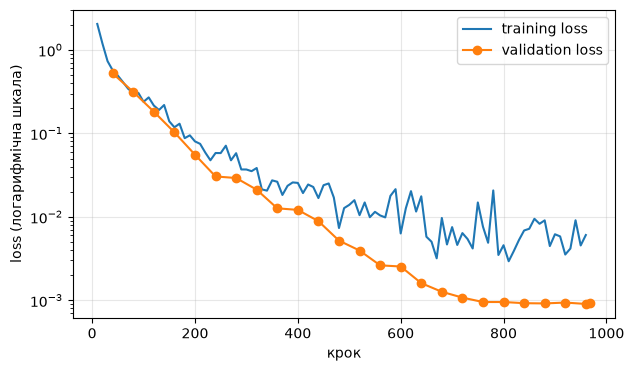

In [25]:
import matplotlib.pyplot as plt

logs = pd.DataFrame(trainer.state.log_history)
train_log = logs[logs["loss"].notna()][["step", "loss"]] if "loss" in logs else pd.DataFrame(columns=["step", "loss"])
eval_log = logs[logs["eval_loss"].notna()][["step", "eval_loss"]]
loss_table = eval_log.merge(train_log, on="step", how="left").rename(
    columns={"step": "Крок", "loss": "Training loss", "eval_loss": "Validation loss"})
display(loss_table.round(4))

plt.figure(figsize=(7, 4))
plt.plot(train_log["step"], train_log["loss"], label="training loss")
plt.plot(eval_log["step"], eval_log["eval_loss"], "o-", label="validation loss")
plt.yscale("log")
plt.xlabel("крок")
plt.ylabel("loss (логарифмічна шкала)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
train_stats["Validation loss"] = eval_log["eval_loss"].iloc[-1]

## 1.5. Порівняння до і після


In [26]:
t0 = time.time()
after = evaluate(trainer.model, SHORT_SYSTEM)
print(f"Оцінка 'після' тривала {(time.time() - t0) / 60:.1f} хв")
after_summary = summarize(after)

compare = pd.concat({"до донавчання": before_summary, "після донавчання": after_summary}, axis=1)
compare

оцінювання: full:   0%|          | 0/4 [00:00<?, ?it/s]

оцінювання: category:   0%|          | 0/3 [00:00<?, ?it/s]

оцінювання: move: 0it [00:00, ?it/s]

оцінювання: unknown: 0it [00:00, ?it/s]

Оцінка 'після' тривала 2.4 хв


до донавчання               після донавчання  \
                              За категорією Повний список    За категорією   
Точний збіг, %                         0.00          0.00            91.67   
Рядки: precision, %                    0.00          0.00            97.08   
Рядки: recall, %                       0.00          0.00            96.18   
Рядки: F1, %                           0.00          0.00            96.23   
Назви: precision, %                    0.17          0.54            97.08   
Назви: recall, %                       0.30          0.42            96.18   
Вигадані назви / відповідь             9.54         23.84             0.12   
Неправильні коди / відповідь           0.02          0.12             0.00   
Пропущені прийоми / відповідь          4.62         29.84             0.21   

                                             
                              Повний список  
Точний збіг, %                        100.0  
Рядки: precision, %                   100.0  
Рядки: recall, %                      100.0  
Рядки: F1, %                          100.0  
Назви: precision, %                   100.0  
Назви: recall, %                      100.0  
Вигадані назви / відповідь              0.0  
Неправильні коди / відповідь            0.0  
Пропущені прийоми / відповідь           0.0

In [27]:
show(pd.concat([after[after.kind == "full"].head(2), after[after.kind == "category"].head(3)]), k=5, chars=500)

❓ List the moves of manon from Street Fighter 6, please.
🤖 Manon — 25 moves

Command Normal:
- 4MK | Classic: 4MK | Modern: 4M
- 4HP | Classic: 4HP | Modern: 4H or A[H]
- 3HK | Classic: 3HK | Modern: --

Target Combo:
- À Terre (5MP~MK) | Classic: 5MP~MK | Modern: 5M~M
- En Haut (4MK~MK) | Classic: 4MK~MK | Modern: 4M~M
- Temps Lié (5HP~HP) | Classic: 5HP~HP | Modern: 5H~H
- Allongé (2HP~HP) | Classic: 2HP~HP | Modern: 2H~H

Throw:
- Forward Throw | Classic: LPLK | Modern: LM
- Back Throw | Classic: 4LPLK | Modern: 4LM

Drive System:
- Drive Impact | Cl …
------------------------------------------------------------
❓ Hey! What's the complete moveset for juri?
🤖 Juri — 25 moves

Command Normal:
- 6MP | Classic: 6MP | Modern: --
- 6MK | Classic: 6MK | Modern: 6M
- 6HP | Classic: 6HP | Modern: 6H
- 4HK | Classic: 4HK | Modern: 4H

Target Combo:
- Death Crest (5MP~4HP~HP) | Classic: 5MP~4HP~HP | Modern: 5M~4M~M

Throw:
- Forward Throw | Classic: LPLK | Modern: LM
- Back Throw | Classic: 4L

### Додаткові тести: один прийом і невідомі персонажі

In [28]:
after_extra = evaluate(trainer.model, SHORT_SYSTEM, test_extra)
compare_extra = pd.concat({"до донавчання": summarize(before_extra), "після донавчання": summarize(after_extra)}, axis=1)
display(compare_extra)
show(pd.concat([after_extra[after_extra.kind == "move"].head(3), after_extra[after_extra.kind == "unknown"].head(3)]), k=6, chars=300)

оцінювання: full: 0it [00:00, ?it/s]

оцінювання: category: 0it [00:00, ?it/s]

оцінювання: move:   0%|          | 0/4 [00:00<?, ?it/s]

оцінювання: unknown:   0%|          | 0/1 [00:00<?, ?it/s]

до донавчання                     \
                                      Один прийом Невідомий персонаж   
Точний збіг, %                               0.00                NaN   
Рядки: precision, %                          0.00                NaN   
Рядки: recall, %                             0.00                NaN   
Рядки: F1, %                                 0.00                NaN   
Назви: precision, %                         40.49                NaN   
Назви: recall, %                            51.56                NaN   
Вигадані назви / відповідь                   1.39                NaN   
Неправильні коди / відповідь                 0.52                NaN   
Пропущені прийоми / відповідь                0.48                NaN   
Відмова (визнав, що даних немає), %           NaN              33.33   

                                    після донавчання                     
                                         Один прийом Невідомий персонаж  
Точний збіг, %                                 35.94                NaN  
Рядки: precision, %                            38.54                NaN  
Рядки: recall, %                               42.19                NaN  
Рядки: F1, %                                   39.58                NaN  
Назви: precision, %                            65.89                NaN  
Назви: recall, %                               71.88                NaN  
Вигадані назви / відповідь                      0.31                NaN  
Неправильні коди / відповідь                    0.30                NaN  
Пропущені прийоми / відповідь                   0.28                NaN  
Відмова (визнав, що даних немає), %              NaN              33.33

❓ Show the Classic and Modern inputs of 4HP for ingrid in Street Fighter 6.
🤖 - 4HP | Classic: 4HP | Modern: 4H
------------------------------------------------------------
❓ Show the Classic and Modern inputs of 6MK for Akuma in Street Fighter 6.
🤖 - 6MK | Classic: 6MK | Modern: 6M
------------------------------------------------------------
❓ Show the Classic and Modern inputs of 4HP for Luke in Street Fighter 6.
🤖 - 4HP | Classic: 4HP | Modern: 4H
------------------------------------------------------------
❓ List the moves of Sol Badguy from Street Fighter 6, please.
🤖 Sol Badguy — 30 moves

Command Normal:
- 6MP | Classic: 6MP | Modern: 6M
- 4HP | Classic: 4HP | Modern: 4H
- 6LK | Classic: 6LK | Modern: 6L
- 6HK | Classic: 6HK | Modern: 6H

Target Combo:
- Middle Step Kick (5MK~HK) | Classic: 5MK~HK | Modern: 5M~M
- Tiger Sting (5HP~HK) | Classic: 5HP~HK | Modern …
------------------------------------------------------------
❓ Hey! What's the complete moveset for Sol Badguy?
🤖 Sol

### Аналіз помилок


In [29]:
errors = after[["character", "kind", "line_f1", "invented", "wrong_inputs", "missed"]]
print("Усього помилок за типами (сума по всіх тестових відповідях):")
print(errors[["invented", "wrong_inputs", "missed"]].sum().rename(
    {"invented": "вигадані назви", "wrong_inputs": "неправильні коди", "missed": "пропущені прийоми"}).to_string())

print("\nНайгірші персонажі за середнім F1 (по рядках):")
display((errors.groupby("character")["line_f1"].mean() * 100).round(1).sort_values().head(8).to_frame("F1, %"))


def diff_lines(pred_text, gold_text):
    pred = Counter(p for p in parse_answer(pred_text) if p[1] is not None)
    gold = Counter(parse_answer(gold_text))
    return list((gold - pred).elements()), list((pred - gold).elements())


worst = after.sort_values("line_f1").head(3)
for r in worst.itertuples():
    missing, extra = diff_lines(r.answer, r.gold)
    print(f"\n=== {r.character} | F1 {r.line_f1:.2%} | {r.question}")
    print("  Немає у відповіді, але є в еталоні:", missing[:5])
    print("  Є у відповіді, але немає в еталоні:", extra[:5])

Усього помилок за типами (сума по всіх тестових відповідях):
вигадані назви        6
неправильні коди      0
пропущені прийоми    10

Найгірші персонажі за середнім F1 (по рядках):


,"F1, %"
character,
Blanka,50.0
Jamie,78.6
Akuma,93.3
Zangief,93.8
Arjun,100.0
C. Viper,100.0
Alex,100.0
A.K.I.,100.0



=== Blanka | F1 0.00% | Please list all Throw entries of blanka in Street Fighter 6.
  Немає у відповіді, але є в еталоні: [('Forward Throw', 'LPLK', 'LM'), ('Back Throw', '4LPLK', '4LM'), ('Air Throw', 'LPLK (air)', 'LM (air)')]
  Є у відповіді, але немає в еталоні: [('Head Throw', '5LPLK', '5LM'), ('Body Throw', '4LPLK', '4LM')]

=== Jamie | F1 57.14% | Please list all Target Combo entries of Jamie in Street Fighter 6.
  Немає у відповіді, але є в еталоні: [('Full Moon Kick (6MK~MK~P)', '6MK~MK~P', '6M~M~M'), ('Intoxicated Assault (4HP~HP~HK)', '4HP~HP~HK', '4H~H~H'), ('Ransui Haze (6HK~4HK~P)', '6HK~4HK~P', '6H~4H~H')]
  Є у відповіді, але немає в еталоні: []

=== Zangief | F1 75.00% | Special Move list for zangief, with Classic and Modern inputs
  Немає у відповіді, але є в еталоні: []
  Є у відповіді, але немає в еталоні: [('Arctic Blast', '22HK', '22H'), ('Frosty Limit Break', '22HK~LK', '22H~L'), ('Freezing Cold Front', '22HK~MK', '22H~M'), ('Cyclone Lariat', '22HK~HK', '22H~H'

### Перевірка загальних відповідей



In [32]:
GENERAL = [
    "What is the capital of Ukraine?",
    "Write a short Python function that checks whether a number is prime.",
    "Translate to Ukrainian: 'Good luck and have fun!'",
    "Explain in two sentences what a neural network is.",
    "Who is Ryu in Street Fighter?",
    "List all moves of Sonic from street fighter.",                                         
    "What is the Modern input for Chun-Li's Drive Parry?",                   
]
HELPER_SYSTEM = "You are a helpful assistant."

ft_model = trainer.model
convs = [msgs(HELPER_SYSTEM, q) for q in GENERAL]
with ft_model.disable_adapter():
    base_answers = generate_batch(ft_model, convs, 200)
tuned_answers = generate_batch(ft_model, convs, 200)

for q, b, t in zip(GENERAL, base_answers, tuned_answers):
    print(f"❓ {q}\n\n  [без адаптера] {b[:400]}\n\n  [з адаптером]  {t[:400]}\n" + "=" * 70)

❓ What is the capital of Ukraine?

  [без адаптера] The capital of Ukraine is Kyiv (also romanized as Kiev). It is the largest city in the country and serves as the political, economic, and cultural center of Ukraine. Kyiv has a rich history that dates back over 2,000 years, and it is home to many historical landmarks, museums, and universities. It is also the seat of the Ukrainian government and the President's official residence.

  [з адаптером]  The capital of Ukraine is Kyiv (also spelled Kiev). It is the largest city in the country and serves as the political, economic, and cultural center of Ukraine. Kyiv has a rich history that dates back over 2,000 years and is home to many historic landmarks, museums, and universities. It is also one of the oldest continuously inhabited cities in Eastern Europe.
❓ Write a short Python function that checks whether a number is prime.

  [без адаптера] Certainly! Below is a simple Python function that checks whether a given number is prime. A pr

## Збереження адаптера й використання

Зберігаємо лише адаптер (десятки або сотні мегабайтів). Щоб скористатися ним пізніше, завантажуємо квантизовану Phi-3.5 і накладаємо адаптер:

```python
from peft import PeftModel
base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb_config, device_map="auto", dtype=DTYPE)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
```

Для 4-бітної моделі **не** варто робити `merge_and_unload`: вливання в квантизовані ваги втрачає точність (на відміну від fp16-моделі з демо 3).

In [33]:
trainer.save_model(ADAPTER_DIR)
adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1e6
print(f"Адаптер: {adapter_mb:.0f} MB (ваги Phi-3.5 у fp16: ~7.6 GB)")


def ask(question, max_new_tokens=MAX_NEW_FULL):
    
    print(generate_batch(trainer.model, [msgs(SHORT_SYSTEM, question)], max_new_tokens)[0])


ask("chun li moves")
ask("juri moves")
ask("sonic moves")

Адаптер: 101 MB (ваги Phi-3.5 у fp16: ~7.6 GB)
Chun-Li — 35 moves

Command Normal:
- 4MP or 6MP | Classic: 4MP or 6MP | Modern: 4M or 6M
- 4HP | Classic: 4HP | Modern: 4H
- 3HP | Classic: 3HP | Modern: --
- 6HK | Classic: 6HK | Modern: 6H
- 3HK | Classic: 3HK | Modern: --
- j.2MK | Classic: j.2MK | Modern: j.2M

Target Combo:
- Soaring Eagle Punches (j.HP~j.HP) | Classic: j.HP~j.HP | Modern: j.A[H~H]
- Yoso Kick Chain (j.2MK~j.2MK~j.2MK) | Classic: j.2MK~j.2MK~j.2MK | Modern: j.2M~j.2M~j.2M

Serenity Stream:
- Serenity Stream | Classic: 214P | Modern: 214X
- Serenity Stream Exit | Classic: 214P~8 | Modern: 214X~8
- Orchid Palm | Classic: 214P~LP | Modern: 214X~5L
- Snake Strike | Classic: 214P~MP | Modern: 214X~5M
- Lotus Fist | Classic: 214P~HP | Modern: 214X~5H
- Forward Strike | Classic: 214P~LK | Modern: 214X~2L
- Senpu Kick | Classic: 214P~MK | Modern: 214X~2M
- Tenku Kick | Classic: 214P~HK | Modern: 214X~2H

Throw:
- Forward Throw | Classic: LPLK | Modern: LM
- Back Throw | Clas

In [34]:
ask("dee jay moves")

Dee Jay — 32 moves

Command Normal:
- 6MK | Classic: 6MK | Modern: 6M
- 4HK | Classic: 4HK | Modern: 4H or A[H]
- j.2LK | Classic: j.2LK | Modern: j.2L

Target Combo:
- Threebeat Combo (5LP~MK~MK) | Classic: 5LP~MK~MK | Modern: 5L~M~M
- Dee Jay Special (5MP~HP~HK) | Classic: 5MP~HP~HK | Modern: 5M~H~H
- Funky Dance (5MP~MP~HP/4HP) | Classic: 5MP~MP~HP/4HP | Modern: 5M~M~M/4M
- Party in the Air (j.MP~j.HP) | Classic: j.MP~j.HP | Modern: j.M~j.M

Throw:
- Forward Throw | Classic: LPLK | Modern: LM
- Back Throw | Classic: 4LPLK | Modern: 4LM

Drive System:
- Drive Impact | Classic: HPHK | Modern: DI
- Drive Reversal | Classic: 6HPHK | Modern: 6DI
- Drive Parry | Classic: MPMK | Modern: DP
- Drive Rush | Classic: MPMK~66 | Modern: DP~66

Special Move:
- Air Slasher | Classic: [4]6P | Modern: [4]6X or [4]S (M)
- Jackknife Maximum | Classic: [2]8K | Modern: [2]8X or [2]S (H)
- Rolling Sobat | Classic: 236K | Modern: 236X or 6S (M)
- Machine Gun Uppercut | Classic: 214P | Modern: 214X
- Jus C

In [35]:
ask("zelenskyi moves")

I don't have a Street Fighter 6 move list for Zelenskyi. I only know the moves of: A.K.I., Akuma, Alex, Arjun, Blanka, C. Viper, Cammy, Chun-Li, Dee Jay, Dhalsim, E. Honda, Ed, Elena, Guile, Ingrid, Jamie, JP, Juri, Ken, Kimberly, Lily, Luke, M. Bison, Mai, Manon, Marisa, Rashid, Ryu, Sagat, Terry, Yasmine, Zangief.
